# FinSense: Financial News Sentiment Analysis Using Machine Learning

**แนวคิด:** พัฒนาระบบ AI ที่วิเคราะห์ข้อความข่าวทางการเงินภาษาอังกฤษ และจำแนกออกเป็น 3 ประเภท ได้แก่
**Positive**, **Negative** และ **Neutral** เพื่อช่วยให้นักลงทุนคัดกรองข่าวเบื้องต้นได้รวดเร็วยิ่งขึ้น

ขั้นตอนของโปรเจกต์ 
1. Problem Definition
2. Data Collection & Loading
3. Exploratory Data Analysis (EDA)
4. Preprocessing
5. Model Training & Selection
6. Evaluation (+ เปรียบเทียบกับ FinBERT)
7. สรุปผล

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.svm import LinearSVC

from finsense_utils import LABELS, STOP_WORDS, clean_text, predict_with_confidence

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
RUN_FINBERT = True   # ตั้งเป็น False หากเครื่องไม่มี transformers/torch หรือไม่มีอินเทอร์เน็ต

# สีตามขั้วของ sentiment: ลบ = แดง, กลาง = เทา, บวก = น้ำเงิน
COLORS = {"negative": "#e34948", "neutral": "#8a8984", "positive": "#2a78d6"}
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 120)
# ฟอนต์ที่รองรับภาษาไทยในกราฟ (Windows: Leelawadee UI/Tahoma, macOS: Thonburi, Linux: Noto Sans Thai)
from matplotlib import font_manager
_installed = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = [f for f in ["Leelawadee UI", "Tahoma", "Thonburi", "Noto Sans Thai"]
                               if f in _installed][:1] + ["DejaVu Sans"]

## 1. Problem Definition

| หัวข้อ | รายละเอียด |
|---|---|
| **ปัญหา** | ข่าวการเงินมีปริมาณมาก นักลงทุนอ่านไม่ทัน ต้องการตัวช่วยคัดกรองว่าข่าวใดเป็นข่าวดี/ข่าวร้าย/ข่าวทั่วไป |
| **ประเภทงาน** | Supervised Learning — Multi-class Text Classification (3 คลาส) |
| **Input** | ประโยคข่าวการเงินภาษาอังกฤษ 1 ประโยค |
| **Output** | `positive`, `negative` หรือ `neutral` |
| **Metric หลัก** | **Macro-F1** เพราะข้อมูลไม่สมดุล (neutral มากกว่าครึ่ง) — accuracy อย่างเดียวจะหลอกตาได้ |
| **Metric รอง** | Accuracy, Precision/Recall ต่อคลาส, Confusion Matrix |

## 2. Data Collection & Loading

ใช้ชุดข้อมูล **Financial PhraseBank** (Malo et al., 2014) — ประโยคจากข่าวการเงินภาษาอังกฤษ ~4,800 ประโยค
ที่ติด label โดยผู้เชี่ยวชาญด้านการเงิน 16 คน (เวอร์ชัน ≥50% agreement, ไฟล์ `all-data.csv` บน Kaggle)

- แหล่งข้อมูล: Kaggle `ankurzing/sentiment-analysis-for-financial-news` หรือ HuggingFace `takala/financial_phrasebank`
- License: CC BY-NC-SA 3.0 (ใช้เพื่อการศึกษาได้)
- รูปแบบไฟล์: ไม่มี header, 2 คอลัมน์ `sentiment, text`, encoding `latin-1`

In [2]:
DATA_PATH = Path("data/all-data.csv")
df = pd.read_csv(DATA_PATH, encoding="latin-1", header=None, names=["sentiment", "text"])
print("ขนาดข้อมูลดิบ:", df.shape)
df.head()

ขนาดข้อมูลดิบ: (4846, 2)


,sentiment,text
0,neutral,"According to Gran , the company has no plans to move all production to Russia , although that is where the company i..."
1,neutral,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies work..."
2,negative,The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; con...
3,positive,With the new production plant the company would increase its capacity to meet the expected increase in demand and wo...
4,positive,"According to the company 's updated strategy for the years 2009-2012 , Basware targets a long-term net sales growth ..."


In [3]:
df.info()
print("\nค่าว่าง:\n", df.isna().sum())
print("\nแถวซ้ำทั้งแถว:", df.duplicated().sum())
print("ข้อความซ้ำ (ไม่สนใจ label):", df["text"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentiment  4846 non-null   object
 1   text       4846 non-null   object
dtypes: object(2)
memory usage: 75.8+ KB

ค่าว่าง:
 sentiment    0
text         0
dtype: int64

แถวซ้ำทั้งแถว: 6
ข้อความซ้ำ (ไม่สนใจ label): 8


**Data cleaning:** ลบค่าว่างและข้อความซ้ำ — ถ้าปล่อยไว้ ประโยคเดียวกันอาจไปอยู่ทั้งใน train และ test
ทำให้คะแนนสูงเกินจริง (data leakage) และบางประโยคซ้ำแต่ label ขัดกัน

In [4]:
df = df.dropna().drop_duplicates(subset="text", keep="first").reset_index(drop=True)
df["sentiment"] = df["sentiment"].str.strip().str.lower()
print("ขนาดหลังทำความสะอาด:", df.shape)

ขนาดหลังทำความสะอาด: (4838, 2)


## 3. Exploratory Data Analysis (EDA)

In [5]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()
df.describe()

,n_chars,n_words
count,4838.000000,4838.000000
mean,128.059529,23.089913
std,56.405552,9.938990
min,9.000000,2.000000
25%,84.000000,16.000000
50%,119.000000,21.000000
75%,163.000000,29.000000
max,315.000000,81.000000


,count,percent
sentiment,,
negative,604,12.5
neutral,2872,59.4
positive,1362,28.2


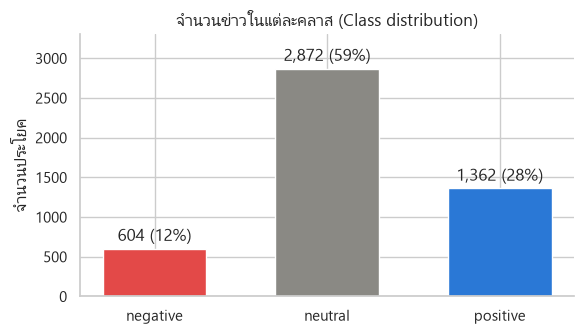

In [6]:
counts = df["sentiment"].value_counts().reindex(LABELS)
display(pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(1)}))

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index, counts.values, color=[COLORS[c] for c in counts.index], width=0.6)
ax.bar_label(bars, labels=[f"{v:,} ({v / counts.sum():.0%})" for v in counts.values], padding=3)
ax.set_title("จำนวนข่าวในแต่ละคลาส (Class distribution)")
ax.set_ylabel("จำนวนประโยค")
ax.margins(y=0.15)
plt.tight_layout(); plt.show()

**ข้อสังเกต:** ข้อมูล **ไม่สมดุล** — neutral ~59%, positive ~28%, negative ~12%
→ ใช้ `stratify` ตอนแบ่งข้อมูล, ใช้ macro-F1 วัดผล และลอง `class_weight="balanced"` ในการจูนโมเดล

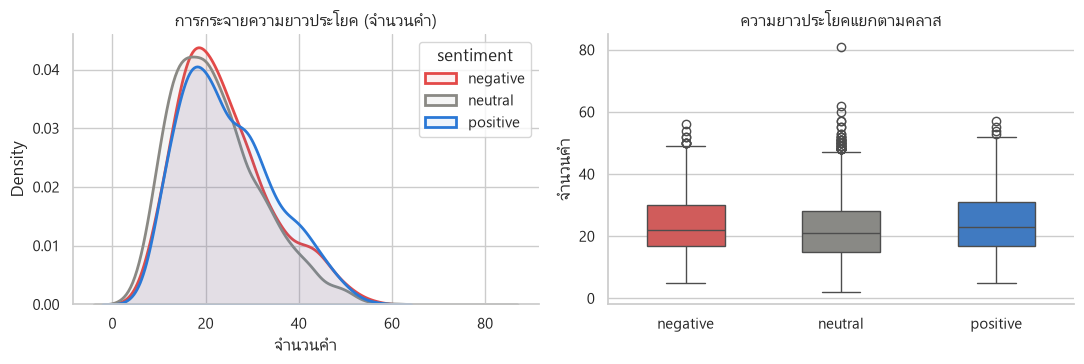

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,604.0,23.917219,9.887414,5.0,17.0,22.0,30.0,56.0
neutral,2872.0,22.161908,9.785539,2.0,15.0,21.0,28.0,81.0
positive,1362.0,24.679883,10.055629,5.0,17.0,23.0,31.0,57.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label in LABELS:
    sns.kdeplot(df.loc[df.sentiment == label, "n_words"], ax=axes[0], label=label,
                color=COLORS[label], linewidth=2, fill=True, alpha=0.08)
axes[0].set_title("การกระจายความยาวประโยค (จำนวนคำ)")
axes[0].set_xlabel("จำนวนคำ"); axes[0].legend(title="sentiment")

sns.boxplot(data=df, x="sentiment", y="n_words", order=LABELS, palette=COLORS, ax=axes[1], width=0.5)
axes[1].set_title("ความยาวประโยคแยกตามคลาส"); axes[1].set_xlabel(""); axes[1].set_ylabel("จำนวนคำ")
plt.tight_layout(); plt.show()

df.groupby("sentiment")["n_words"].describe().reindex(LABELS)

ความยาวประโยคของทั้ง 3 คลาสใกล้เคียงกัน (~20–25 คำ) จึงไม่ใช่ feature ที่แยกคลาสได้ — ต้องอาศัย **คำ** ในประโยค

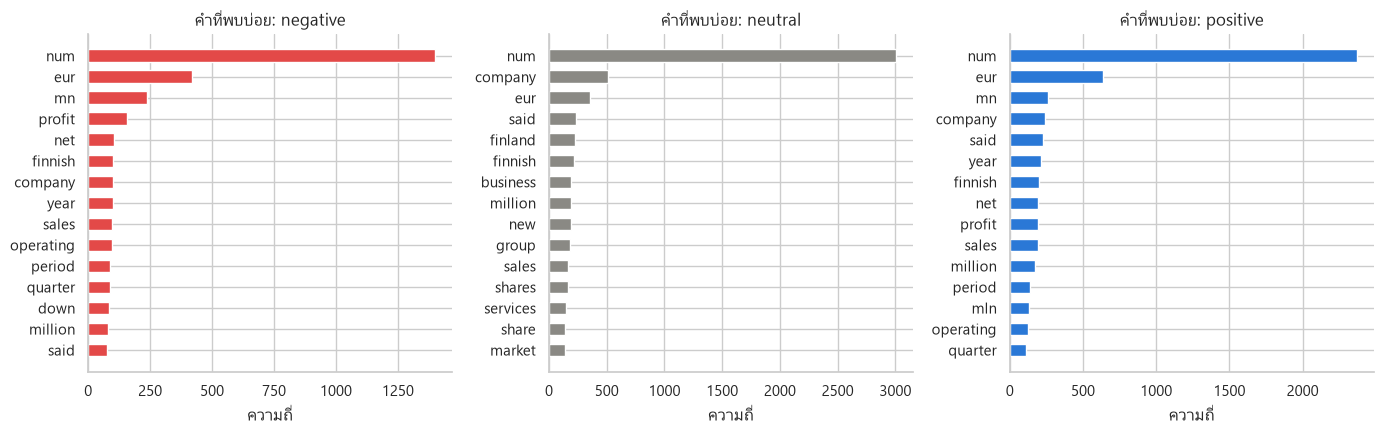

In [8]:
def top_words(texts, n=15):
    cv = CountVectorizer(preprocessor=clean_text, stop_words=STOP_WORDS)
    X = cv.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(cv.get_feature_names_out())
    idx = freq.argsort()[::-1][:n]
    return pd.Series(freq[idx], index=vocab[idx])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, label in zip(axes, LABELS):
    tw = top_words(df.loc[df.sentiment == label, "text"])
    ax.barh(tw.index[::-1], tw.values[::-1], color=COLORS[label], height=0.6)
    ax.set_title(f"คำที่พบบ่อย: {label}")
    ax.set_xlabel("ความถี่")
plt.tight_layout(); plt.show()

**ข้อสังเกต:** คำที่พบบ่อยที่สุดของทั้ง 3 คลาสแทบเหมือนกัน (*num, eur, mn, company, profit, sales*) — มีเพียง *down* ที่โผล่ใน top ของ negative
แปลว่า **ความถี่ของคำอย่างเดียวแยกคลาสไม่ได้** สิ่งที่แยกคลาสคือคำบอกทิศทางที่พบไม่บ่อยแต่มีน้ำหนักสูง (เช่น *rose, increased* vs *fell, decreased*)
ซึ่งเป็นเหตุผลที่ใช้ **TF-IDF** (ลดน้ำหนักคำที่พบทุกที่) และ **เก็บคำอย่าง up/down ไว้ไม่ให้ถูกตัดเป็น stop words** — ดูน้ำหนักคำจริงในหัวข้อ 6.2

In [9]:
for label in LABELS:
    print(f"--- {label.upper()} ---")
    for t in df.loc[df.sentiment == label, "text"].sample(3, random_state=RANDOM_STATE):
        print("  •", t)

--- NEGATIVE ---
  • The company decided at the end of 2008 to temporarily shut down its ammonia plant in Billingham and extend the maintenance period at its Ince facility .
  • down to EUR5 .9 m H1 '09 3 August 2009 - Finnish media group Ilkka-Yhtyma Oyj ( HEL : ILK2S ) said today its net profit fell 45 % on the year to EUR5 .9 m in the first half of 2009 .
  • The steelmaker said that the drop in profit was explained by the continuing economic uncertainty , mixed with the current drought in bank lending , resulting in a decline in demand for its products as customers find it increasingly difficult to fund operations .
--- NEUTRAL ---
  • The total investment necessary will be EUR40m , the company estimated .
  • According to product manager Lassi Hietanen , building a power plant that burns mixed waste in Helsinki may not be a good idea because this reduces the production of combined power plants using natural gas .
  • The company 's US subsidiary Vaisala Inc. acquires Aviation Syst

## 4. Preprocessing

1. **Text cleaning** (`clean_text` ใน `finsense_utils.py`): ตัวพิมพ์เล็ก, ลบ URL, แปลง `n't` → `not`,
   แทนตัวเลขด้วยโทเคน `num`, ลบเครื่องหมายวรรคตอน
2. **Stop words:** ใช้ stop words ภาษาอังกฤษของ scikit-learn แต่ **เก็บ** คำที่มีความหมายเชิงทิศทาง เช่น
   *not, no, up, down, above, below, more, less* (ปล่อยให้ GridSearch เลือกว่าจะตัดหรือไม่)
3. **Feature extraction:** `TfidfVectorizer` (แทน `StandardScaler` ใน structure.txt เพราะข้อมูลเป็นข้อความ)
4. ทุกขั้นอยู่ใน **`Pipeline`** เดียว → ไม่มี data leakage ระหว่าง cross-validation และบันทึกไปใช้งานจริงได้ทั้งก้อน

In [10]:
examples = ["Operating profit rose to EUR 13.1 mn from EUR 8.7 mn in 2007.",
            "The company didn't meet expectations; shares fell 5% (see www.example.com)."]
for e in examples:
    print(e, "\n  →", clean_text(e))

Operating profit rose to EUR 13.1 mn from EUR 8.7 mn in 2007. 
  → operating profit rose to eur num mn from eur num mn in num
The company didn't meet expectations; shares fell 5% (see www.example.com). 
  → the company did not meet expectations shares fell num see


### 4.1 แบ่งข้อมูล Train / Validation / Test (70 / 15 / 15)

| ชุดข้อมูล | สัดส่วน | ใช้ทำอะไร |
|---|---|---|
| **Train** | 70% | เทรนโมเดล + จูน hyperparameter ด้วย GridSearchCV (5-fold CV ภายใน train) |
| **Validation** | 15% | **เลือกชนิดโมเดล** — เทียบโมเดลที่ดีที่สุดของแต่ละชนิดบนข้อมูลที่ไม่ได้ใช้เทรน |
| **Test** | 15% | วัดผลโมเดลสุดท้าย **ครั้งเดียว** ตอนจบ ไม่ใช้ตัดสินใจใด ๆ |

แบ่ง 2 ขั้นด้วย `train_test_split(..., stratify=y)` เพื่อให้ทุกชุดมีสัดส่วนคลาสเท่ากัน:
แยก test 15% ออกก่อน → แบ่งส่วนที่เหลือเป็น train/validation

sentiment,negative,neutral,positive,total,percent
Train,422,2010,954,3386,70.0
Validation,91,431,204,726,15.0
Test,91,431,204,726,15.0


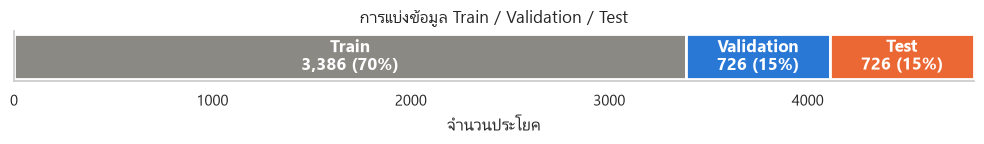

In [11]:
X, y = df["text"], df["sentiment"]
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.15 / 0.85, stratify=y_trval, random_state=RANDOM_STATE)

SPLITS = {"Train": (X_train, y_train, "#8a8984"),
          "Validation": (X_val, y_val, "#2a78d6"),
          "Test": (X_test, y_test, "#eb6834")}
split_table = pd.DataFrame({name: ys.value_counts().reindex(LABELS) for name, (_, ys, _) in SPLITS.items()}).T
split_table["total"] = split_table.sum(axis=1)
split_table["percent"] = (split_table["total"] / len(X) * 100).round(1)
display(split_table)

fig, ax = plt.subplots(figsize=(10, 1.6))
left = 0
for name, (xs, _, color) in SPLITS.items():
    ax.barh(0, len(xs), left=left, color=color, height=0.6, edgecolor="white", linewidth=2)
    ax.text(left + len(xs) / 2, 0, f"{name}\n{len(xs):,} ({len(xs) / len(X):.0%})",
            ha="center", va="center", color="white", fontweight="bold")
    left += len(xs)
ax.set_xlim(0, len(X)); ax.set_yticks([]); ax.set_xlabel("จำนวนประโยค")
ax.set_title("การแบ่งข้อมูล Train / Validation / Test"); ax.grid(False)
plt.tight_layout(); plt.show()

In [12]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(preprocessor=clean_text, sublinear_tf=True)),
    ("model", LogisticRegression()),   # placeholder — GridSearch จะสลับโมเดล
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",<function cle...002324C101300>
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


## 5. Model Training & Selection

ขั้นที่ 1 — **จูน hyperparameter บน Train:** ใช้ **GridSearchCV (5-fold Stratified CV, scoring = macro-F1)**
หาค่าที่ดีที่สุดของแต่ละชนิดโมเดล โดยสลับ step `model` ใน Pipeline

ขั้นที่ 2 — **เลือกชนิดโมเดลบน Validation set** (หัวข้อ 5.1)

| โมเดล | เหตุผลที่เลือก | Hyperparameters |
|---|---|---|
| Multinomial Naive Bayes | baseline คลาสสิกสำหรับข้อความ เร็ว | `alpha` |
| Logistic Regression | linear model ตีความได้ ให้ความน่าจะเป็น | `C`, `class_weight` |
| Linear SVM | มักดีที่สุดกับ TF-IDF มิติสูง | `C`, `class_weight` |
| Random Forest | ensemble แบบ non-linear เพื่อเปรียบเทียบ | `max_depth`, `class_weight` |

TF-IDF: `ngram_range` (unigram / unigram+bigram), `min_df`, `stop_words`

In [13]:
tfidf_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "tfidf__stop_words": [None, STOP_WORDS],
}
param_grid = [
    {**tfidf_grid, "model": [MultinomialNB()], "model__alpha": [0.1, 0.5, 1.0]},
    {**tfidf_grid, "model": [LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)],
     "model__C": [1, 10, 30], "model__class_weight": [None, "balanced"]},
    {**tfidf_grid, "model": [LinearSVC(random_state=RANDOM_STATE)],
     "model__C": [0.1, 0.5, 1], "model__class_weight": [None, "balanced"]},
    {"tfidf__ngram_range": [(1, 1)], "tfidf__min_df": [2],
     "model": [RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)],
     "model__max_depth": [None, 60], "model__class_weight": [None, "balanced"]},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, verbose=1)
gs.fit(X_train, y_train)

print("Best CV macro-F1 (ทุกชนิดรวมกัน):", round(gs.best_score_, 4))

Fitting 5 folds for each of 124 candidates, totalling 620 fits


Best CV macro-F1 (ทุกชนิดรวมกัน): 0.7253


In [14]:
res = pd.DataFrame(gs.cv_results_)
res["model_name"] = res["param_model"].apply(lambda m: type(m).__name__)
best_idx = res.groupby("model_name")["mean_test_score"].idxmax()
best_per_model = (res.loc[best_idx, ["model_name", "mean_test_score", "std_test_score", "mean_fit_time", "params"]]
                  .sort_values("mean_test_score", ascending=False).reset_index(drop=True))
best_per_model[["model_name", "mean_test_score", "std_test_score", "mean_fit_time"]].round(4)

,model_name,mean_test_score,std_test_score,mean_fit_time
0,LogisticRegression,0.7253,0.0217,2.5939
1,LinearSVC,0.7230,0.0224,0.2420
2,MultinomialNB,0.6730,0.0234,0.2006
3,RandomForestClassifier,0.6699,0.0230,3.2677


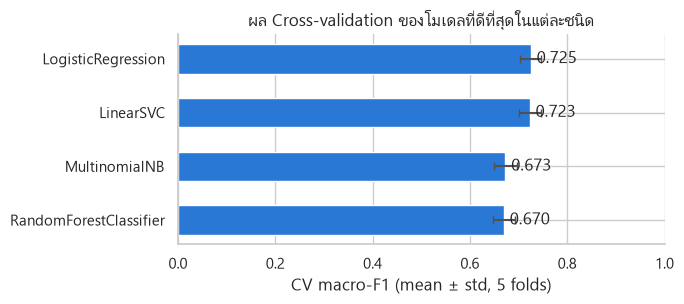

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bp = best_per_model.iloc[::-1]
ax.barh(bp["model_name"], bp["mean_test_score"], xerr=bp["std_test_score"],
        color="#2a78d6", height=0.55, error_kw={"ecolor": "#52514e", "capsize": 3})
for i, v in enumerate(bp["mean_test_score"]):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("CV macro-F1 (mean ± std, 5 folds)")
ax.set_title("ผล Cross-validation ของโมเดลที่ดีที่สุดในแต่ละชนิด")
plt.tight_layout(); plt.show()

### 5.1 เลือกโมเดลด้วย Validation set

นำ hyperparameter ที่ดีที่สุดของแต่ละชนิดมาเทรนบน **Train** แล้ววัดผลบน **Validation** (ข้อมูลที่ GridSearch ไม่เคยเห็น)
โมเดลที่ได้ **validation macro-F1 สูงสุด** คือโมเดลสุดท้าย — test set ยังไม่ถูกแตะเลยในขั้นนี้

,model,cv_macro_f1,val_accuracy,val_macro_f1
0,LinearSVC,0.7230,0.7948,0.7451
1,LogisticRegression,0.7253,0.7948,0.7388
2,MultinomialNB,0.6730,0.7672,0.7131
3,RandomForestClassifier,0.6699,0.7645,0.6969


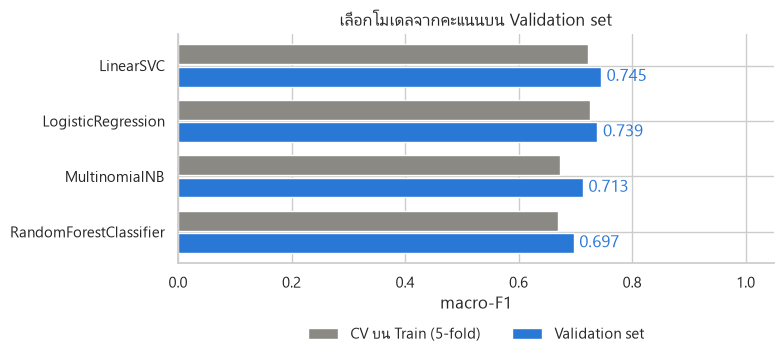

โมเดลที่เลือก: LinearSVC
  model__C: 0.5
  model__class_weight: balanced
  tfidf__min_df: 2
  tfidf__ngram_range: (1, 2)
  tfidf__stop_words: None


In [16]:
val_rows = []
for _, r in best_per_model.iterrows():
    m = clone(pipe).set_params(**r["params"]).fit(X_train, y_train)
    p = m.predict(X_val)
    val_rows.append({"model": r["model_name"], "cv_macro_f1": r["mean_test_score"],
                     "val_accuracy": accuracy_score(y_val, p),
                     "val_macro_f1": f1_score(y_val, p, average="macro"),
                     "params": r["params"]})
val_compare = pd.DataFrame(val_rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(val_compare.drop(columns="params").round(4))

fig, ax = plt.subplots(figsize=(8, 3.9))
order = val_compare.iloc[::-1]
ypos = np.arange(len(order))
ax.barh(ypos + 0.2, order["cv_macro_f1"], height=0.36, color="#8a8984", label="CV บน Train (5-fold)")
ax.barh(ypos - 0.2, order["val_macro_f1"], height=0.36, color="#2a78d6", label="Validation set")
for i, v in enumerate(order["val_macro_f1"]):
    ax.text(v + 0.01, i - 0.2, f"{v:.3f}", va="center", color="#2a78d6")
ax.set_yticks(ypos, order["model"]); ax.set_xlim(0, 1.05); ax.set_xlabel("macro-F1")
ax.set_title("เลือกโมเดลจากคะแนนบน Validation set")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

FINAL_NAME = val_compare.loc[0, "model"]
best_params = val_compare.loc[0, "params"]
print("โมเดลที่เลือก:", FINAL_NAME)
for k, v in best_params.items():
    if k != "model":
        print(f"  {k}: {'custom list' if k == 'tfidf__stop_words' and v is not None else v}")

## 6. Evaluation

หลังเลือกโมเดลได้แล้ว นำ **Train + Validation** มาเทรนโมเดลสุดท้ายอีกครั้ง (ได้ข้อมูลเทรนมากขึ้น โดยไม่เปลี่ยน hyperparameter ที่เลือกไว้)
แล้ววัดผลบน **Test set (15%)** ที่ไม่เคยถูกใช้ในการตัดสินใจใด ๆ — นี่คือคะแนนที่สะท้อนการใช้งานจริง

In [17]:
best_model = clone(pipe).set_params(**best_params).fit(X_trval, y_trval)
y_pred = best_model.predict(X_test)
print(f"Final model: {FINAL_NAME}  (เทรนบน Train+Validation = {len(X_trval):,} ประโยค)")
print(classification_report(y_test, y_pred, labels=LABELS, digits=3))

Final model: LinearSVC  (เทรนบน Train+Validation = 4,112 ประโยค)
              precision    recall  f1-score   support

    negative      0.714     0.714     0.714        91
     neutral      0.801     0.879     0.838       431
    positive      0.741     0.588     0.656       204

    accuracy                          0.777       726
   macro avg      0.752     0.727     0.736       726
weighted avg      0.773     0.777     0.772       726



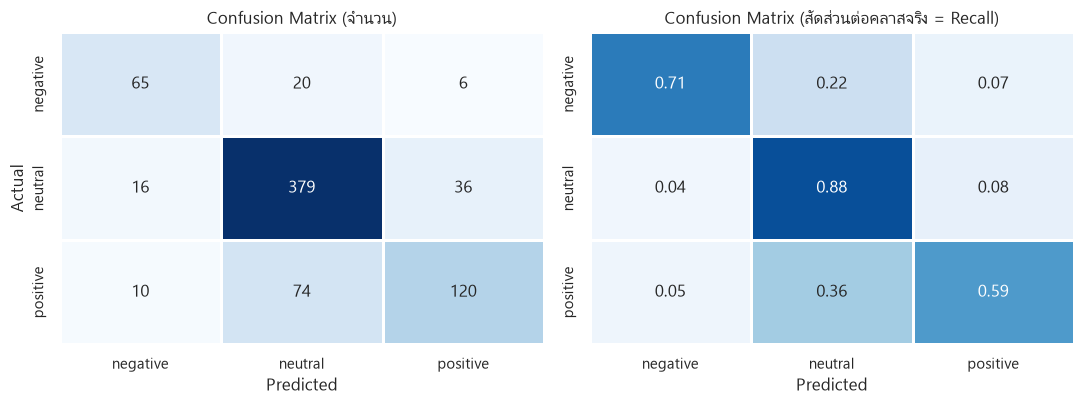

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = confusion_matrix(y_test, y_pred, labels=LABELS)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Confusion Matrix (จำนวน)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
cm_norm = confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1, linewidths=2,
            linecolor="white", xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Confusion Matrix (สัดส่วนต่อคลาสจริง = Recall)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

### 6.0 พัฒนาการของโมเดล: Learning Curve

โมเดล TF-IDF + SVM ไม่ได้เทรนเป็นรอบ (epoch) แบบ deep learning จึงไม่มีกราฟ loss ต่อ epoch
วิธีมาตรฐานที่ใช้ดูว่า **AI เก่งขึ้นอย่างไร** คือ *learning curve* — เทรนโมเดลด้วยข้อมูลจำนวนเพิ่มขึ้นทีละขั้น
แล้ววัดคะแนนด้วย 5-fold CV (ใช้เฉพาะ train set ไม่แตะ test set)

- **Training score** = คะแนนบนข้อมูลที่โมเดลเห็นแล้ว
- **Validation score** = คะแนนบนข้อมูลที่โมเดลไม่เคยเห็น (ตัวที่สำคัญจริง)

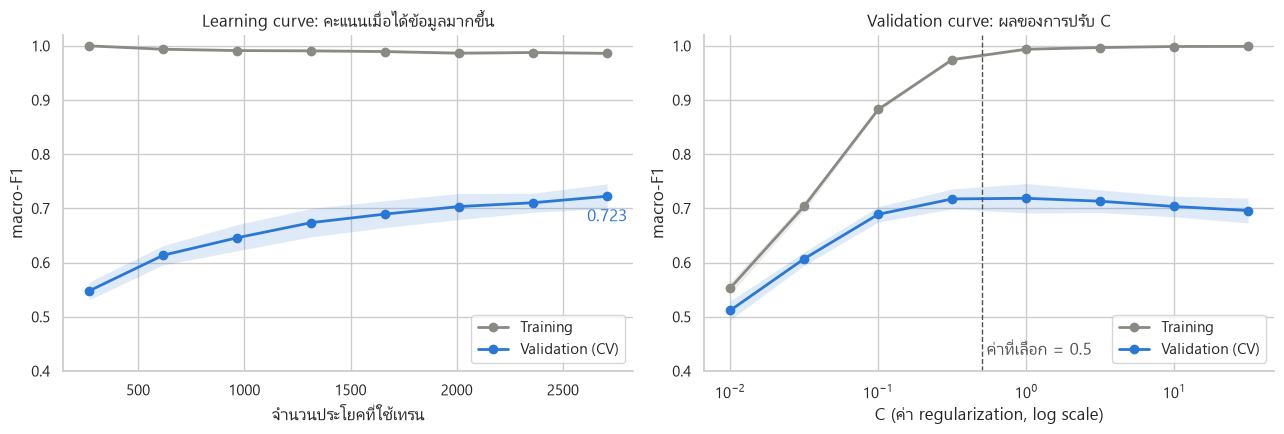

,train_size,train_f1,val_f1
0,270,1.000,0.548
1,618,0.994,0.614
2,967,0.991,0.646
3,1315,0.991,0.674
4,1663,0.990,0.690
5,2011,0.987,0.704
6,2359,0.988,0.711
7,2708,0.986,0.723


In [19]:
from sklearn.model_selection import learning_curve, validation_curve

def plot_curve(ax, x, train_scores, val_scores, xlabel, logx=False):
    for scores, name, color in [(train_scores, "Training", "#8a8984"), (val_scores, "Validation (CV)", "#2a78d6")]:
        mean, std = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(x, mean, "o-", color=color, linewidth=2, markersize=6, label=name)
        ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.15, linewidth=0)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel); ax.set_ylabel("macro-F1"); ax.set_ylim(0.4, 1.02)
    ax.legend(loc="lower right")

sizes, lc_train, lc_val = learning_curve(
    best_model, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8),
    cv=cv, scoring="f1_macro", n_jobs=-1)

if "model__C" in best_params:   # LR / SVM ใช้ C, Naive Bayes ใช้ alpha
    param_name, param_range, param_label = "model__C", np.logspace(-2, 1.5, 8), "C (ค่า regularization, log scale)"
else:
    param_name, param_range, param_label = "model__alpha", np.logspace(-3, 1, 8), "alpha (smoothing, log scale)"
vc_train, vc_val = validation_curve(
    clone(best_model), X_train, y_train, param_name=param_name, param_range=param_range,
    cv=cv, scoring="f1_macro", n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_curve(axes[0], sizes, lc_train, lc_val, "จำนวนประโยคที่ใช้เทรน")
axes[0].set_title("Learning curve: คะแนนเมื่อได้ข้อมูลมากขึ้น")
axes[0].annotate(f"{lc_val.mean(axis=1)[-1]:.3f}", (sizes[-1], lc_val.mean(axis=1)[-1]),
                 textcoords="offset points", xytext=(0, -18), ha="center", color="#2a78d6")

plot_curve(axes[1], param_range, vc_train, vc_val, param_label, logx=True)
chosen = best_params.get(param_name)
if chosen is not None:
    axes[1].axvline(chosen, color="#52514e", linestyle="--", linewidth=1)
    axes[1].text(chosen, 0.43, f" ค่าที่เลือก = {chosen}", color="#52514e")
axes[1].set_title(f"Validation curve: ผลของการปรับ {param_name.split('__')[1]}")
plt.tight_layout(); plt.show()

pd.DataFrame({"train_size": sizes, "train_f1": lc_train.mean(axis=1),
              "val_f1": lc_val.mean(axis=1)}).round(3)

**อ่านกราฟ**
- **Learning curve (ซ้าย):** validation macro-F1 เพิ่มจาก ~0.55 (เทรน ~270 ประโยค) เป็น ~0.72 (เทรน ~2,700 ประโยค)
  และเส้น **ยังไม่แบนราบ** → ถ้าเพิ่มข้อมูลอีก โมเดลน่าจะเก่งขึ้นได้อีก
- training score อยู่ที่ ~0.99 ตลอด ห่างจาก validation มาก → โมเดล **จำข้อมูลเทรนได้เกือบหมด (high variance)**
  ซึ่งเป็นเรื่องปกติของ TF-IDF ที่มีหลายหมื่นมิติ วิธีลดช่องว่างคือเพิ่มข้อมูล
- **Validation curve (ขวา):** C น้อยเกินไป (regularize มาก) → underfit ทั้งสองเส้นต่ำ; C มากเกินไป → validation ลดลงเล็กน้อย (overfit)
  จุดที่ดีที่สุดอยู่ช่วง C ≈ 0.3–1 ซึ่งตรงกับค่าที่ GridSearch เลือก

### 6.1 คะแนนของทุกโมเดลบน Test set (เพื่ออ้างอิง)

ตารางนี้ **ไม่ได้ใช้เลือกโมเดล** (เลือกไปแล้วจาก validation ในหัวข้อ 5.1) — แสดงเพื่อดูว่าการจัดอันดับบน validation
สอดคล้องกับ test หรือไม่ ทุกโมเดลเทรนบน Train+Validation เหมือนโมเดลสุดท้าย

In [20]:
rows = []
fitted = {}
for _, r in val_compare.iterrows():
    m = clone(pipe).set_params(**r["params"]).fit(X_trval, y_trval)
    p = m.predict(X_test)
    fitted[r["model"]] = m
    rows.append({"model": r["model"], "cv_macro_f1": r["cv_macro_f1"], "val_macro_f1": r["val_macro_f1"],
                 "test_accuracy": accuracy_score(y_test, p),
                 "test_macro_f1": f1_score(y_test, p, average="macro")})
compare = pd.DataFrame(rows).reset_index(drop=True)
compare.round(4)

,model,cv_macro_f1,val_macro_f1,test_accuracy,test_macro_f1
0,LinearSVC,0.7230,0.7451,0.7769,0.7362
1,LogisticRegression,0.7253,0.7388,0.7727,0.7355
2,MultinomialNB,0.6730,0.7131,0.7300,0.6722
3,RandomForestClassifier,0.6699,0.6969,0.7410,0.6709


### 6.2 คำที่มีผลต่อการตัดสินใจของโมเดล (Interpretability)

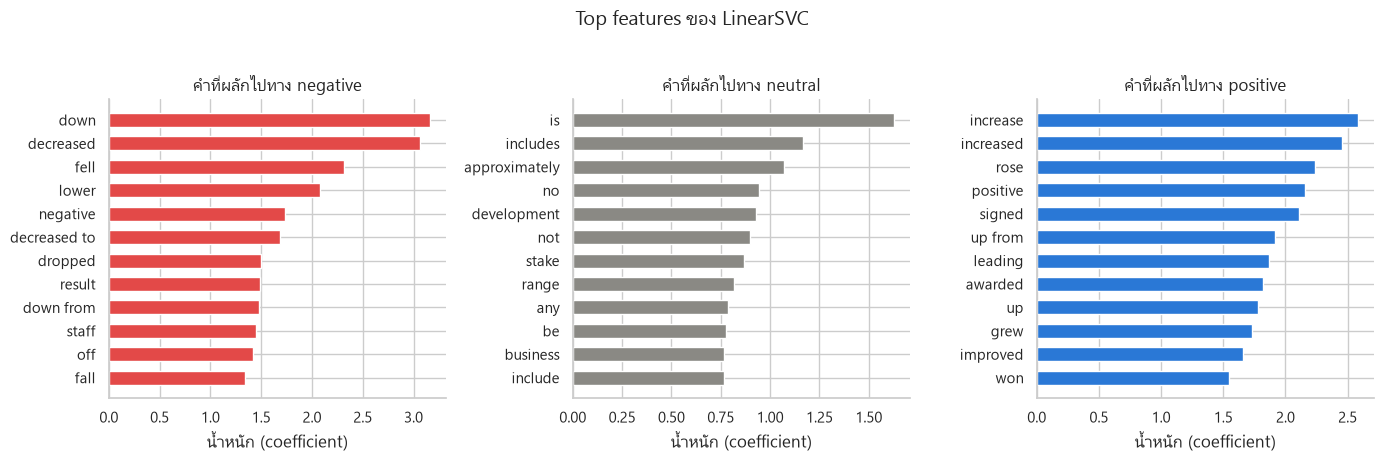

In [21]:
# ใช้โมเดลเชิงเส้น (LR หรือ SVM) เพื่อดูน้ำหนักของคำ
linear_name = next(n for n in compare["model"] if n in ("LogisticRegression", "LinearSVC"))
lin = fitted[linear_name]
vocab = lin.named_steps["tfidf"].get_feature_names_out()
coefs = lin.named_steps["model"].coef_
classes = list(lin.named_steps["model"].classes_)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, label in zip(axes, LABELS):
    w = coefs[classes.index(label)]
    top = w.argsort()[::-1][:12]
    ax.barh(vocab[top][::-1], w[top][::-1], color=COLORS[label], height=0.6)
    ax.set_title(f"คำที่ผลักไปทาง {label}")
    ax.set_xlabel("น้ำหนัก (coefficient)")
fig.suptitle(f"Top features ของ {linear_name}", y=1.02)
plt.tight_layout(); plt.show()

### 6.3 วิเคราะห์ตัวอย่างที่ทายผิด (Error analysis)

In [22]:
errors = pd.DataFrame({"text": X_test, "actual": y_test, "predicted": y_pred})
errors = errors[errors.actual != errors.predicted]
print(f"ทายผิด {len(errors)} จาก {len(y_test)} ประโยค ({len(errors) / len(y_test):.1%})")
print(errors.groupby(["actual", "predicted"]).size().sort_values(ascending=False).to_string())
errors.sample(min(10, len(errors)), random_state=RANDOM_STATE)

ทายผิด 162 จาก 726 ประโยค (22.3%)
actual    predicted
positive  neutral      74
neutral   positive     36
negative  neutral      20
neutral   negative     16
positive  negative     10
negative  positive      6


,text,actual,predicted
4441,Stora Enso 's target has been cut to EUR 4.85 from EUR 5.55 and Holmen 's target -- to SEK 135 from SEK 150 .,negative,positive
59,"In Sweden , Gallerix accumulated SEK denominated sales were down 1 % and EUR denominated sales were up 11 % .",neutral,negative
4263,"The prosecutor is also demanding Outokumpu pay a fine of EUR 800,000 at most .",negative,neutral
1423,The solutions will be used for upgrading the networks of a Russian MSO in 37 different cities in Russia .,positive,neutral
4591,"The highest growth would be in China , while weakening demand would continue in North America , UPM said .",neutral,positive
1016,"According to Ultrascan , with a software acquired from crackers , it has managed to change the mobile phone in a way...",neutral,positive
3614,"In addition , the company will reduce a maximum of ten jobs .",negative,neutral
823,"As a domestic business , Best-In is already close to Finnish dog owners .",positive,neutral
1768,`` These patronage refunds reward members that use the fee-based services that make a positive contribution to CenCo...,neutral,positive
4439,Ramirent made 18 million kroons EUR 1.15 mln loss last year ; the year before the company was 7.3 million kroons in ...,negative,neutral


**ข้อสังเกตที่พบบ่อย:** ความผิดพลาดส่วนใหญ่เกิดระหว่าง *positive ↔ neutral* — ประโยคที่มีตัวเลขเพิ่ม/ลดแต่ไม่มีคำบอกทิศทางชัดเจน
หรือประโยคที่ต้องอาศัยการตีความเชิงบริบท (เช่น "costs decreased" เป็นข่าวดี) ซึ่ง bag-of-words จับไม่ได้

### 6.4 ทดลองกับข่าวใหม่

In [23]:
new_news = [
    "Company profit rose 20% year-on-year, beating analyst expectations.",
    "The firm reported a net loss and announced it will cut 500 jobs.",
    "The annual general meeting will be held in Helsinki on 15 March.",
    "Shares plunged after the CEO resigned amid an accounting scandal.",
    "Net sales increased to EUR 120 million from EUR 95 million.",
]
labels, proba = predict_with_confidence(best_model, new_news)
classes = list(best_model.classes_)
pd.DataFrame({"news": new_news, "prediction": labels,
              "confidence": proba.max(axis=1).round(3)})

,news,prediction,confidence
0,"Company profit rose 20% year-on-year, beating analyst expectations.",positive,0.777
1,The firm reported a net loss and announced it will cut 500 jobs.,negative,0.512
2,The annual general meeting will be held in Helsinki on 15 March.,neutral,0.711
3,Shares plunged after the CEO resigned amid an accounting scandal.,neutral,0.646
4,Net sales increased to EUR 120 million from EUR 95 million.,positive,0.772


ตัวอย่างอย่าง *"Shares plunged after the CEO resigned..."* อาจถูกทายเป็น neutral เพราะคำว่า *plunged, scandal, resigned*
แทบไม่มีในข้อมูล train — เป็นข้อจำกัดของ bag-of-words ที่รู้จักเฉพาะคำที่เคยเห็น (FinBERT แก้ปัญหานี้ได้ดีกว่า)

### 6.5 บันทึกโมเดล

In [24]:
MODEL_PATH = Path("models/finsense_model.joblib")
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(best_model, MODEL_PATH)
print("Saved →", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1024:.0f} KB)")
assert (joblib.load(MODEL_PATH).predict(X_test) == y_pred).all()

Saved → models\finsense_model.joblib (578 KB)


### 6.6 เปรียบเทียบกับ FinBERT (Deep Learning baseline)

**FinBERT** (`ProsusAI/finbert`) คือ BERT ที่ถูก pre-train บนข้อความการเงินและ fine-tune สำหรับ sentiment
ใช้แบบ inference อย่างเดียวบน test set เดียวกัน

> ⚠️ **ข้อควรระวัง:** FinBERT ถูก fine-tune บน Financial PhraseBank มาแล้ว ประโยคใน test set ของเราจึงอาจเคยอยู่ใน
> training data ของ FinBERT → คะแนนอาจ **สูงเกินจริง** ใช้เป็นตัวอ้างอิงเพดานความสามารถ ไม่ใช่การแข่งขันที่ยุติธรรม 100%

In [25]:
finbert_result = None
if RUN_FINBERT:
    try:
        import os, time
        os.environ["USE_TF"] = "0"   # บังคับใช้ PyTorch (กันปัญหา TensorFlow/Keras 3)
        from transformers import pipeline as hf_pipeline

        finbert = hf_pipeline("text-classification", model="ProsusAI/finbert",
                              framework="pt", truncation=True)
        t0 = time.time()
        out = finbert(list(X_test), batch_size=32)
        finbert_secs = time.time() - t0
        finbert_pred = np.array([o["label"].lower() for o in out])
        finbert_result = {"model": "FinBERT (ProsusAI)", "cv_macro_f1": np.nan, "val_macro_f1": np.nan,
                          "test_accuracy": accuracy_score(y_test, finbert_pred),
                          "test_macro_f1": f1_score(y_test, finbert_pred, average="macro")}
        print(f"FinBERT inference: {finbert_secs:.1f}s สำหรับ {len(X_test)} ประโยค")
        print(classification_report(y_test, finbert_pred, labels=LABELS, digits=3))
    except Exception as e:
        print("ข้าม FinBERT:", e)
else:
    print("RUN_FINBERT = False → ข้ามส่วนนี้")

Device set to use cpu


FinBERT inference: 87.8s สำหรับ 726 ประโยค
              precision    recall  f1-score   support

    negative      0.774     0.978     0.864        91
     neutral      0.952     0.833     0.889       431
    positive      0.791     0.907     0.845       204

    accuracy                          0.872       726
   macro avg      0.839     0.906     0.866       726
weighted avg      0.884     0.872     0.873       726



,model,cv_macro_f1,val_macro_f1,test_accuracy,test_macro_f1
0,RandomForestClassifier,0.6699,0.6969,0.7410,0.6709
1,MultinomialNB,0.6730,0.7131,0.7300,0.6722
2,LogisticRegression,0.7253,0.7388,0.7727,0.7355
3,LinearSVC,0.7230,0.7451,0.7769,0.7362
4,FinBERT (ProsusAI),NaN,NaN,0.8719,0.8658


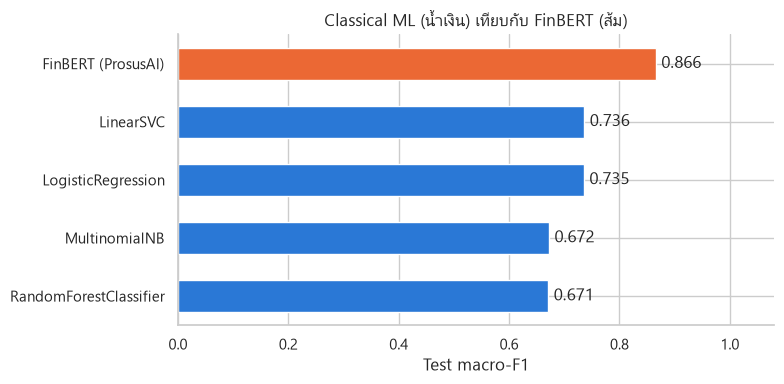

In [26]:
final = compare.copy()
if finbert_result:
    final = pd.concat([final, pd.DataFrame([finbert_result])], ignore_index=True)
final = final.sort_values("test_macro_f1").reset_index(drop=True)
display(final.round(4))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(final) + 1))
is_bert = final["model"].str.startswith("FinBERT")
ax.barh(final["model"], final["test_macro_f1"], height=0.55,
        color=np.where(is_bert, "#eb6834", "#2a78d6"))
for i, v in enumerate(final["test_macro_f1"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.08); ax.set_xlabel("Test macro-F1")
ax.set_title("Classical ML (น้ำเงิน) เทียบกับ FinBERT (ส้ม)")
plt.tight_layout(); plt.show()

## 7. สรุปผล

- สร้าง pipeline **TF-IDF + Classifier** สำหรับจำแนก sentiment ข่าวการเงิน 3 คลาส แบ่งข้อมูล **Train / Validation / Test = 70 / 15 / 15**
  จูน hyperparameter ด้วย GridSearchCV บน train และเลือกชนิดโมเดลด้วย validation set — test set ใช้ครั้งเดียวตอนจบ
- โมเดลที่เลือกคือ **Linear SVM** (validation macro-F1 ≈ 0.745) ได้ **test macro-F1 ≈ 0.74, accuracy ≈ 0.78**
  ใกล้เคียงคะแนน validation แปลว่าโมเดลไม่ได้ overfit กับ validation set และอันดับโมเดลบน test ตรงกับบน validation
- Logistic Regression ได้คะแนนใกล้เคียงกันมาก (ต่างกันน้อยกว่าค่า std ของ CV) — โมเดลเชิงเส้นเหมาะกับ TF-IDF: เร็ว เบา อธิบายได้ด้วยน้ำหนักของคำ
- **Learning curve** แสดงว่าคะแนน validation ยังเพิ่มขึ้นตามจำนวนข้อมูล (0.55 → 0.72) — การหาข้อมูลเพิ่มคือทางพัฒนาที่คุ้มที่สุด
- ความผิดพลาดส่วนใหญ่คือ **positive → neutral** — โมเดลระวังเกินไปในการตัดสินว่าเป็นข่าวดี
- คลาส **negative** มีข้อมูลน้อยที่สุด การใช้ `class_weight="balanced"` และวัดผลด้วย macro-F1 ช่วยไม่ให้โมเดลมองข้ามคลาสนี้
- **FinBERT** ได้คะแนนสูงกว่า (macro-F1 ≈ 0.87) เพราะเข้าใจบริบทของประโยค แต่ใช้ทรัพยากรมากกว่ามาก (โมเดล ~440 MB เทียบกับ < 1 MB, inference ช้ากว่าหลายร้อยเท่าบน CPU)
  และคะแนนอาจสูงเกินจริงเนื่องจากเคยเห็นข้อมูลชุดนี้

**ข้อจำกัด**
- Bag-of-words ไม่เข้าใจลำดับคำ/บริบท เช่น "loss narrowed" (ข่าวดี) หรือ "costs decreased"
- ข้อมูลเป็นข่าวบริษัทฟินแลนด์ช่วงปี 2004–2011 อาจไม่ครอบคลุมภาษาข่าวปัจจุบัน
- จำแนกระดับประโยค ไม่ใช่ระดับบทความ และไม่ได้บอกว่า sentiment นั้นเกี่ยวกับบริษัทใด

**งานในอนาคต**
- Fine-tune transformer (เช่น FinBERT/DeBERTa) บน train split ของเราเองเพื่อเทียบอย่างยุติธรรม
- เพิ่มข้อมูลข่าวใหม่ / ข่าวจาก Twitter และทำ aspect-based sentiment (แยกตามบริษัท)
- เชื่อมกับ news API เพื่อคัดกรองข่าวแบบ real-time (ต่อยอดจาก `app.py`)